# Presentación



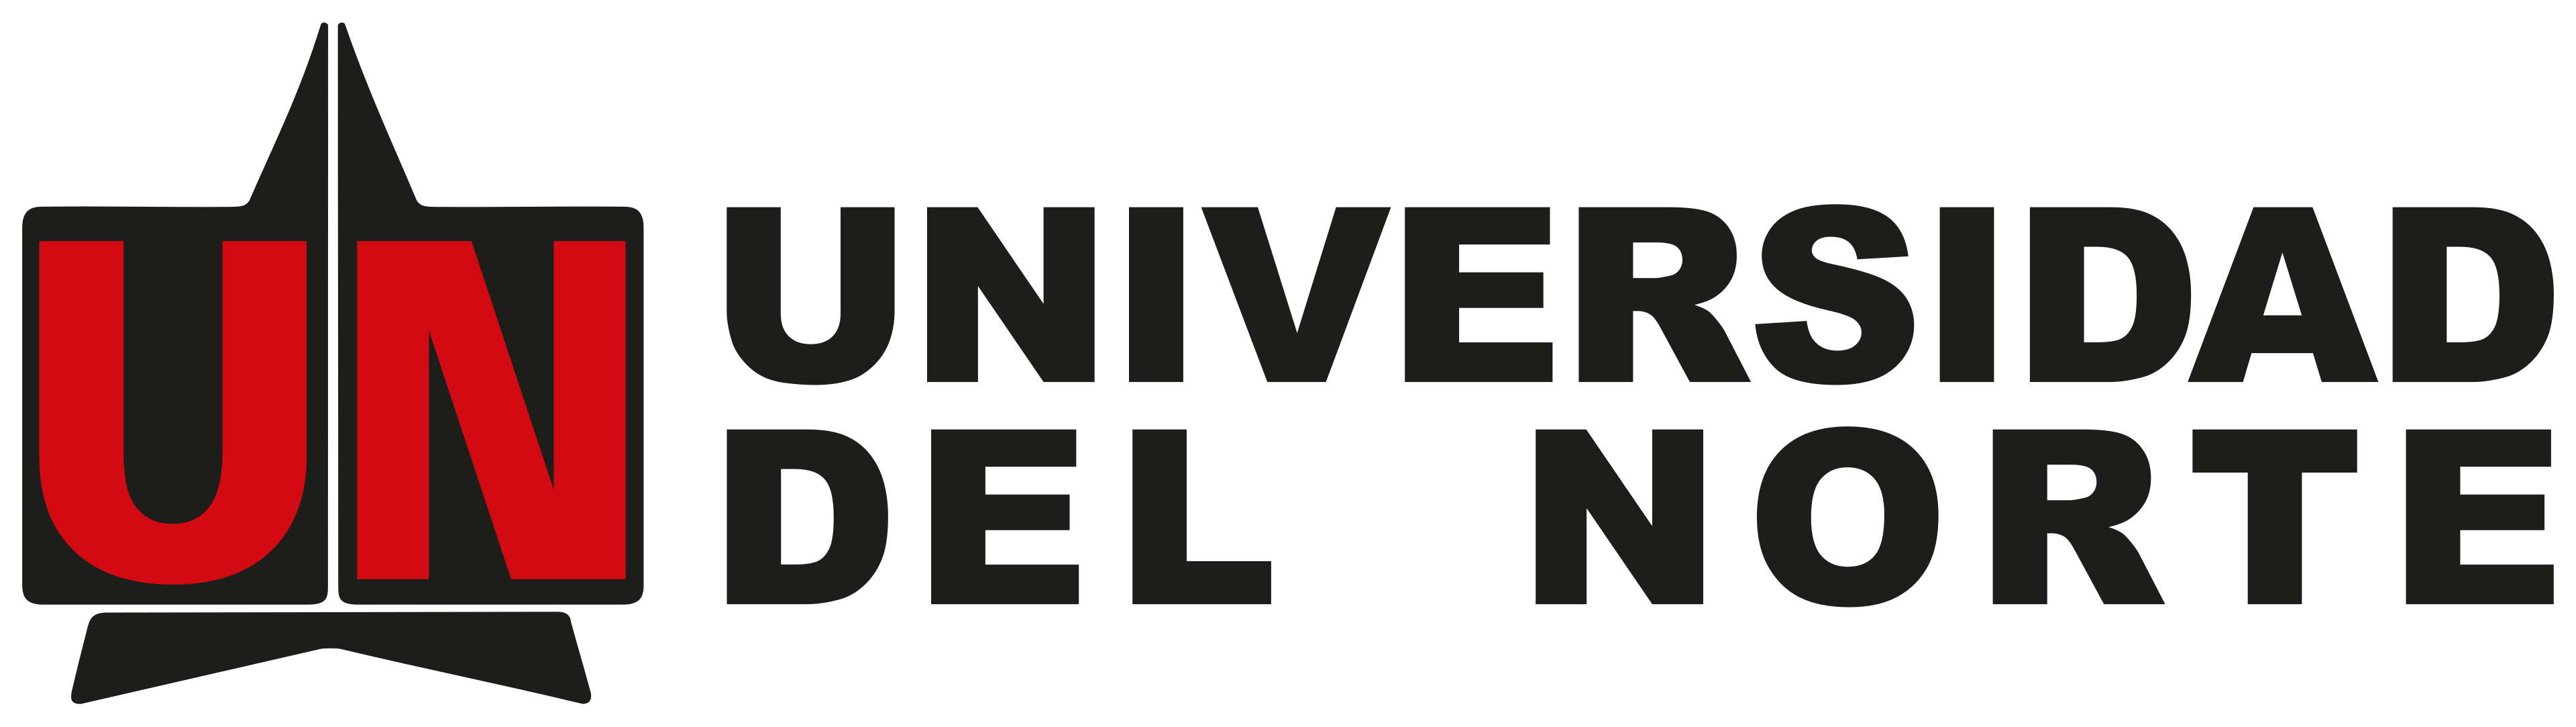
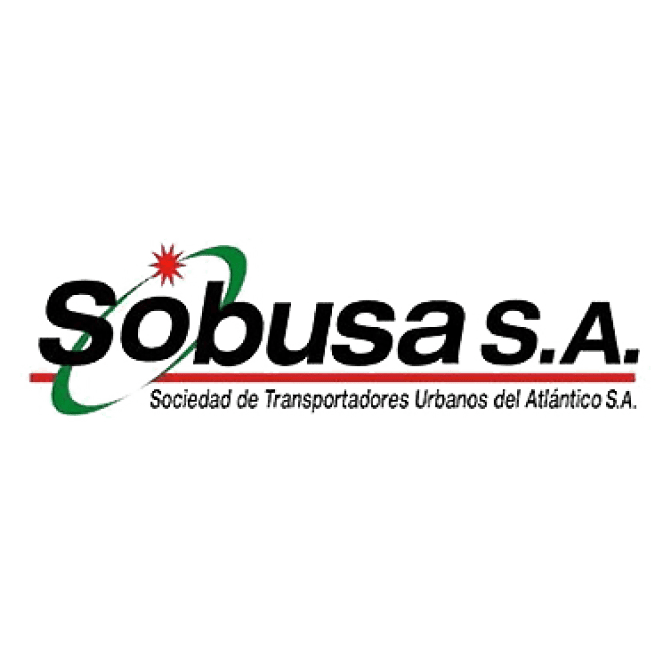
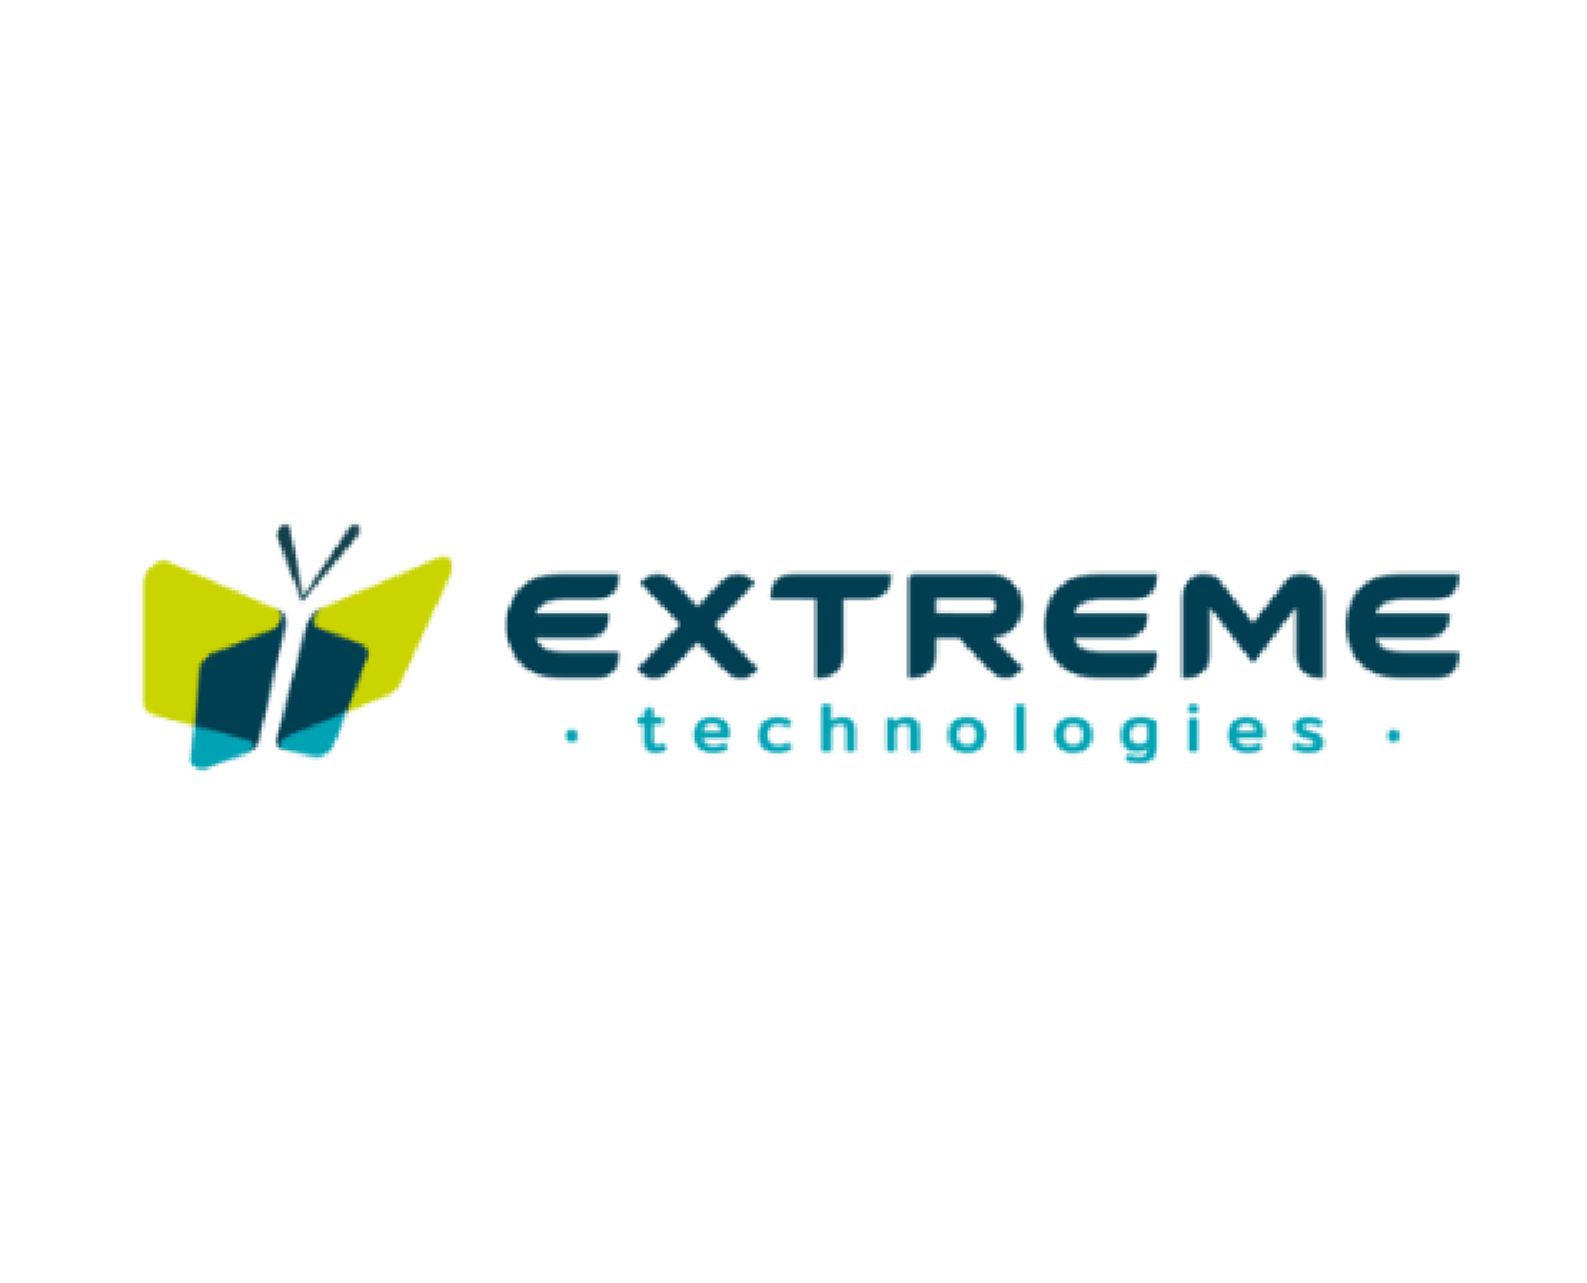
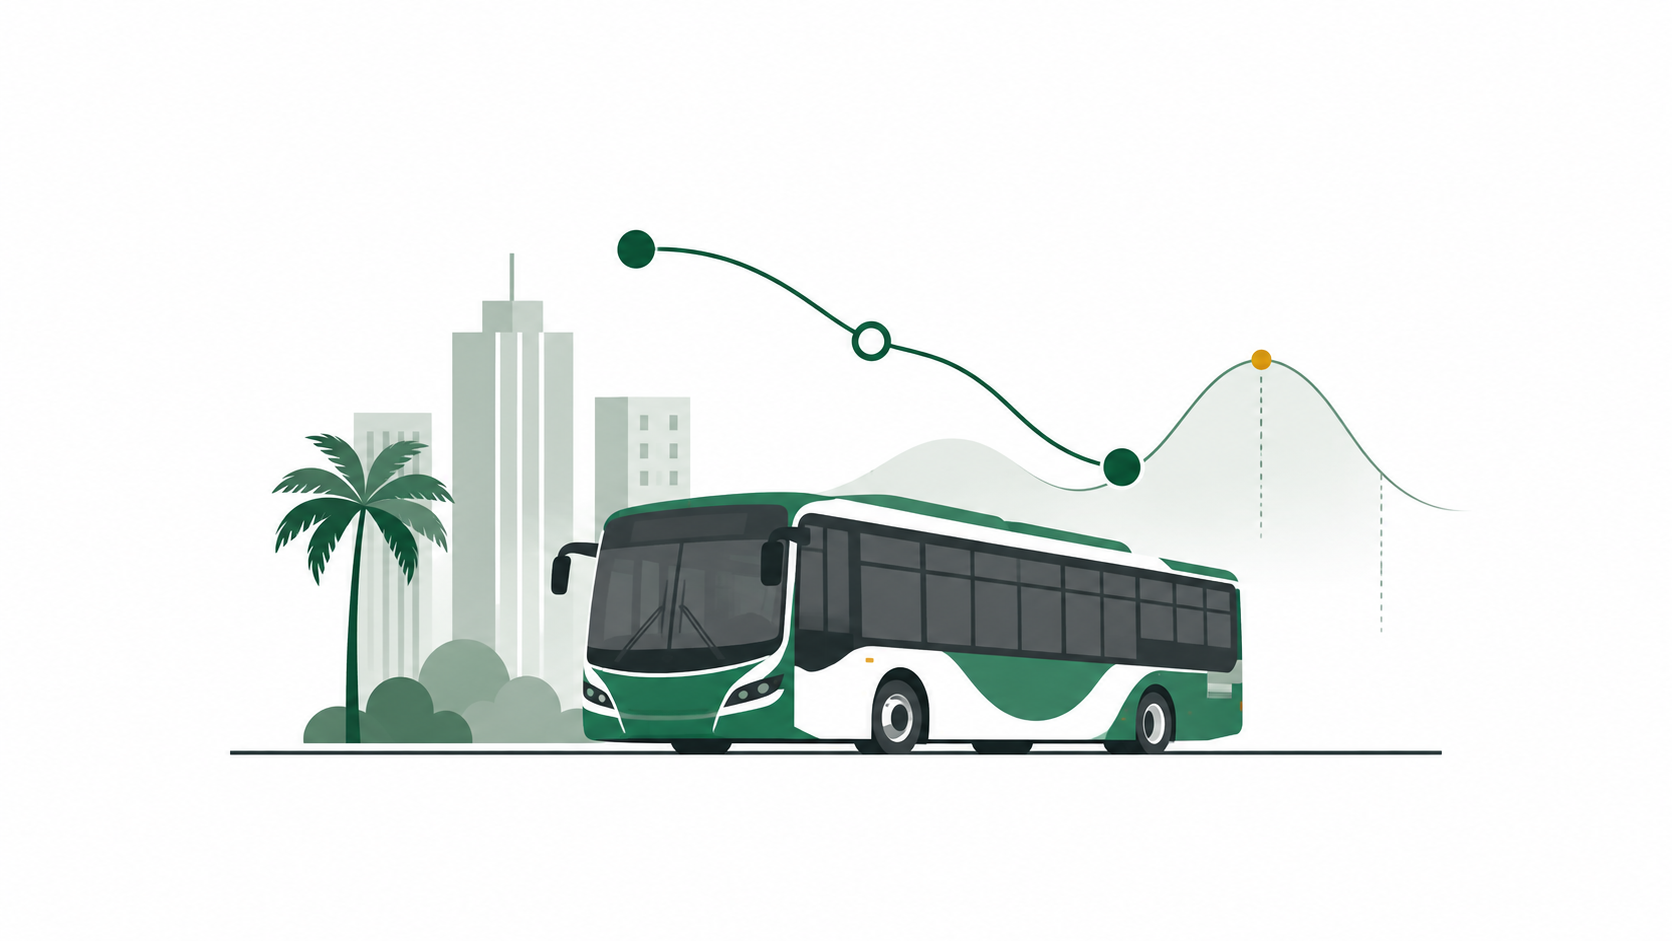

In [12]:
from pathlib import Path
import base64
import mimetypes
from IPython.display import HTML, display

# CAMBIA AQUÍ LOS NOMBRES REALES DE TUS IMÁGENES
imagenes = {
    "uninorte": "logo_uninorte.png",
    "sobusa": "logo_sobusa.png",
    "extreme": "logo_extreme.png",
    "ilustracion": "ilustracion_sobusa.png",
}

carpeta = Path("imagenes")

def incorporar_imagen(nombre):
    archivo = carpeta / nombre

    if not archivo.is_file():
        raise FileNotFoundError(
            f"No encuentro la imagen: {archivo.resolve()}"
        )

    tipo = mimetypes.guess_type(archivo.name)[0] or "image/png"
    contenido = base64.b64encode(archivo.read_bytes()).decode("ascii")
    return f"data:{tipo};base64,{contenido}"

img = {
    clave: incorporar_imagen(nombre)
    for clave, nombre in imagenes.items()
}

portada = f"""
<div style="
    max-width:1100px;
    margin:0 auto;
    padding:30px 12px;
    text-align:center;
    font-family:Arial, Helvetica, sans-serif;
">

    <div style="
        display:flex;
        justify-content:center;
        align-items:center;
        flex-wrap:wrap;
        gap:32px;
        margin-bottom:40px;
    ">
        <img src="{img['uninorte']}"
             alt="Universidad del Norte"
             style="width:220px;max-width:28%;height:85px;object-fit:contain;">

        <img src="{img['sobusa']}"
             alt="SOBUSA"
             style="width:240px;max-width:28%;height:205px;object-fit:contain;">

        <img src="{img['extreme']}"
             alt="Extreme Technologies"
             style="width:220px;max-width:28%;height:205px;object-fit:contain;">
    </div>

    <h1 style="
        color:#176B3A;
        font-size:clamp(26px, 3.5vw, 40px);
        font-weight:750;
        line-height:1.2;
        margin:0 0 20px;
    ">
        Analítica de datos para la planificación
        del servicio de transporte de SOBUSA
    </h1>

    <p style="
        color:#333333;
        font-size:clamp(18px, 2vw, 24px);
        line-height:1.45;
        margin:0 auto 18px;
        max-width:950px;
    "><strong>
        Calidad de datos, análisis exploratorio y fundamentos
        para el pronóstico de pasajeros y la recomendación de despachos
    </strong></p>

    <p style="
        color:#666666;
        font-size:15px;
        letter-spacing:0.3px;
        margin:0 0 30px;
    ">
        Data Challenge 2026
    </p>

    <div style="
        height:3px;
        background:#208C48;
        width:100%;
        margin-bottom:30px;
    "></div>

    <img src="{img['ilustracion']}"
         alt="Ilustración conceptual del transporte urbano,
              el análisis de pasajeros y la planificación de despachos"
         style="
            display:block;
            width:100%;
            max-width:1000px;
            height:auto;
            margin:0 auto;
            border-radius:12px;
         ">

    <p style="
        color:#777777;
        font-size:12px;
        margin-top:12px;
    ">
    </p>

</div>
"""

# Oculta el código en Jupyter Book y conserva la portada visible.
etiqueta = "remove-input"
display(HTML(portada))

**Integrantes**

Daniela Hernández · Alejandra Meneses · Maringel Yepes



## **1. Contexto y planteamiento del problema**

La planificación del transporte requiere comprender cómo cambia el uso del servicio entre rutas, horarios y días, y cómo se relaciona con la oferta disponible. Esta información permite identificar períodos de mayor afluencia, estudiar diferencias operativas y fundamentar decisiones sobre la separación entre despachos, la frecuencia del servicio y la asignación de vehículos.

En el marco del Data Challenge 2026, el proyecto busca desarrollar una base analítica para anticipar los conteos de pasajeros en horizontes de **30, 60 y 120 minutos** y apoyar recomendaciones operativas que consideren capacidad, disponibilidad de flota y restricciones del servicio. El propósito comprende tanto la generación de pronósticos como la comunicación de su incertidumbre, sus fundamentos y las condiciones bajo las cuales pueden utilizarse.

Los datos disponibles combinan programaciones, conteos de subidas y bajadas, registros por segmentos, catálogos de rutas y vehículos, y agregados históricos. Cada fuente representa una unidad de observación diferente y puede tener una cobertura temporal distinta. Por ello, su integración exige verificar qué mide cada variable, a qué período pertenece y cómo se relaciona con las demás tablas.

El problema central consiste en **transformar registros operativos heterogéneos en información confiable y comparable**, sin confundir ausencia de medición con ausencia de pasajeros, programaciones con servicios efectivamente realizados, ni abordajes acumulados con ocupación simultánea.

El proyecto aborda este problema mediante un flujo reproducible de extracción, auditoría, preparación y análisis exploratorio. Esta etapa establece qué información puede utilizarse para describir la operación y qué condiciones deben cumplirse antes de construir modelos predictivos o recomendaciones de despacho.


## **2. Objetivos**

### **2.1. Objetivo general**

Desarrollar una base analítica reproducible para las rutas de SOBUSA, mediante la integración, validación y exploración de sus datos operativos, que permita caracterizar el uso observado del servicio y sustentar posteriormente el pronóstico de pasajeros y la recomendación de despachos bajo restricciones operativas.

### **2.2. Objetivos específicos**

1. **Caracterizar las fuentes de información**, documentando su estructura, significado, unidades, llaves, cobertura temporal y relación con la operación.

2. **Implementar una extracción reproducible y verificable**, preservando los tipos de datos y registrando los filtros, períodos y resultados de cada ejecución.

3. **Evaluar la calidad de los datos**, identificando faltantes, duplicados, inconsistencias temporales, valores fuera de las reglas de validez y problemas de integridad relacional.

4. **Preparar conjuntos de análisis coherentes**, con unidades de observación y criterios de inclusión explícitos, evitando duplicaciones por uniones y modificaciones injustificadas de los registros originales.

5. **Describir las variables y sus relaciones**, mediante análisis univariado, bivariado y temporal que permita reconocer distribuciones, diferencias entre rutas y patrones de calendario.

6. **Definir las condiciones para el pronóstico**, incluyendo la variable objetivo, la resolución temporal, los horizontes de predicción y la información disponible en el momento de emitir cada pronóstico.

7. **Establecer fundamentos para las recomendaciones operativas**, vinculando los pronósticos con capacidad, frecuencia y disponibilidad de flota, e incorporando incertidumbre y restricciones verificadas.

### **2.3. Preguntas orientadoras**

- ¿Qué fuentes permiten describir cada ruta y qué períodos cubren?
- ¿Qué registros son utilizables y qué limitaciones afectan su interpretación?
- ¿Cómo varían los conteos registrados entre rutas, días y horarios?
- ¿Las diferencias observadas corresponden a más programaciones, a más pasajeros por programación o a cambios en la cobertura?
- ¿Qué relaciones pueden aportar información para anticipar conteos futuros?
- ¿Qué información adicional se necesita para convertir un pronóstico en una recomendación de despacho viable?

## **3. Marco teórico aplicado**

### 3.1. Uso observado del servicio y demanda de transporte

La demanda de transporte comprende las necesidades de desplazamiento de las personas. Los registros operativos permiten observar una parte de esa demanda: el uso del servicio que efectivamente queda medido.

Un abordaje representa una entrada a un vehículo. Una misma persona puede generar varios abordajes durante un desplazamiento si realiza transbordos. Esta distinción coincide con el concepto de *unlinked passenger trips* de la Federal Transit Administration, que contabiliza cada abordaje y no identifica personas únicas. Se utiliza aquí como referencia conceptual, sin adoptar sus disposiciones como regulación colombiana.

Para este proyecto, los conteos registrados deben interpretarse según su definición y cobertura. Las personas que no pudieron abordar, desistieron o utilizaron otro servicio no quedan necesariamente representadas. Por tanto, un conteo bajo puede estar relacionado con menor uso observado, menor oferta o menor disponibilidad de medición; los datos deben permitir distinguir estas posibilidades antes de formular una conclusión.

### 3.2. Oferta, frecuencia y separación entre despachos

La oferta del servicio comprende los recursos y servicios dispuestos para atender los desplazamientos: vehículos, despachos, horarios y capacidad disponible. Una programación expresa un servicio previsto; para describir la oferta efectivamente realizada es necesario verificar su ejecución.

La **frecuencia** indica cuántos despachos se producen por unidad de tiempo. La **separación entre despachos**, o *headway*, expresa el tiempo entre servicios consecutivos. Bajo intervalos uniformes:

$$
f=\frac{60}{h}
$$

donde $f$ es la frecuencia en despachos por hora y $h$ es la separación en minutos. Con intervalos irregulares, el promedio debe acompañarse de una medida de variabilidad.

El *Transit Capacity and Quality of Service Manual*, en su cuarta edición publicada en 2026, proporciona un marco actualizado para estudiar capacidad, operación y calidad del servicio. Sus métodos sirven como referencia técnica; las decisiones concretas requieren adaptación a las condiciones y restricciones de SOBUSA.

### 3.3. Abordajes, bajadas y ocupación

Los abordajes acumulados durante una programación no equivalen al número de personas presentes simultáneamente dentro del vehículo. Un bus puede transportar, a lo largo de su operación, más personas que su capacidad nominal debido a la renovación de pasajeros.

Conceptualmente, la carga a bordo puede reconstruirse mediante:

$$
L_s=L_{s-1}+S_s-B_s
$$

donde $L_s$ es la carga después del segmento o parada $s$, $S_s$ son las subidas y $B_s$ las bajadas. Esta relación exige conocer la carga inicial, el orden de los registros y la correspondencia entre las mediciones.

El porcentaje de ocupación requiere, además, una capacidad válida:

$$
O_s=100\frac{L_s}{C}
$$

Por ello, la ocupación solo puede calcularse cuando ambas magnitudes están confirmadas. Los valores negativos, capacidades ausentes o diferencias entre subidas y bajadas deben investigarse antes de atribuirles un significado operativo.

### 3.4. Calidad de datos y trazabilidad

La utilidad de los datos depende de su adecuación al análisis previsto. En este proyecto, la calidad se evalúa mediante seis aspectos: **cobertura, completitud, unicidad, validez, consistencia y trazabilidad**.

La cobertura identifica las rutas, fechas y servicios representados. La completitud mide la disponibilidad de campos necesarios. La unicidad permite reconocer repeticiones según la unidad de observación. La validez comprueba reglas documentadas. La consistencia examina la coherencia entre campos y fuentes. La trazabilidad conserva evidencia del origen y de las transformaciones realizadas.

Estos aspectos se evalúan por uso. Una tabla puede ser suficiente para estudiar programaciones mensuales y resultar insuficiente para reconstruir ocupación por segmento. Asimismo, un faltante, un cero registrado y un valor inválido representan situaciones diferentes y requieren tratamientos distintos.

### 3.5. Integración relacional y nivel de observación

Antes de combinar fuentes debe definirse qué representa cada fila: vehículo, programación, segmento, evento o celda agregada.

Esta definición determina las llaves y la cardinalidad esperada de las uniones. Por ejemplo, una programación puede tener múltiples registros por segmento. Al unir ambas tablas, sus atributos se repetirán; promediar o sumar posteriormente esos atributos sin controlar la repetición puede distorsionar los resultados.

La integración debe conservar el nivel requerido por cada pregunta. Cuando sea necesario, el detalle se agregará antes de la unión. Las comparaciones entre rutas también deben utilizar períodos, definiciones y denominadores equivalentes.

### 3.6. Análisis exploratorio y asociación estadística

El análisis exploratorio permite comprender la estructura de los datos, reconocer patrones y detectar observaciones que requieren revisión antes de modelar. El NIST lo plantea como un enfoque que combina herramientas gráficas y cuantitativas para examinar los datos y evaluar supuestos.

El análisis univariado describe cada variable mediante frecuencias, medidas de posición y dispersión. El bivariado estudia relaciones y diferencias entre variables. El análisis temporal incorpora el orden de las observaciones y su evolución.

En SOBUSA, estos análisis deben distinguir volumen total registrado, cantidad de programaciones y conteo por programación. Además, una asociación no demuestra causalidad: las diferencias entre vehículos o rutas pueden reflejar horarios, asignaciones o coberturas distintas. Los extremos estadísticos tampoco constituyen, por sí solos, errores.

### 3.7. Pronóstico temporal e incertidumbre

El pronóstico estima valores futuros a partir de información disponible hasta un momento determinado. Para construirlo deben definirse la variable objetivo, el intervalo de agregación y el horizonte de predicción.

Los modelos deberán compararse con referencias sencillas, como el último valor observado o un patrón estacional. Su evaluación debe simular el uso futuro mediante cortes cronológicos y orígenes de pronóstico sucesivos, examinando por separado los horizontes de 30, 60 y 120 minutos. También deberán acompañarse de intervalos o cuantiles que expresen incertidumbre. Estas prácticas forman parte del marco de evaluación de *Forecasting: Principles and Practice*.

El desempeño se examinará por ruta, horizonte y franja horaria, además del resultado global. Esto permitirá identificar dónde el modelo aporta información útil y dónde requiere mejoras.

### 3.8. Fuga de información y disponibilidad de variables

La fuga de información ocurre cuando un modelo utiliza datos que no estarían disponibles al emitir el pronóstico. Esto puede producir una evaluación demasiado optimista.

En el proyecto, el riesgo incluye utilizar conteos finales para anticipar una programación aún no terminada, incorporar agregados calculados con observaciones futuras o aprender imputaciones y escalados con todo el conjunto. Las transformaciones aprendidas deben ajustarse únicamente con los datos de entrenamiento. La documentación de scikit-learn explica este principio y el uso de pipelines para mantener la separación entre entrenamiento y evaluación.

Cada variable predictora deberá documentar tanto el período que representa como el momento en que estaría disponible. Una variable útil para describir el pasado no queda automáticamente habilitada para pronosticar.

### 3.9. Del pronóstico a la recomendación operativa

Un pronóstico de pasajeros es un insumo para decidir, pero no determina por sí solo cuántos buses deben despacharse.

La recomendación deberá considerar capacidad efectiva, carga en los puntos críticos, tiempo de ciclo, disponibilidad de vehículos, regularidad y restricciones operativas. También deberá valorar la incertidumbre: una recomendación basada únicamente en el promedio puede resultar insuficiente ante escenarios de mayor afluencia.

El resultado esperado es una propuesta verificable que explique **qué se recomienda, con qué información, bajo qué supuestos y con qué límites**. Cuando falte un parámetro indispensable, deberán presentarse escenarios explícitos o dejar la decisión pendiente de validación.